# Load useful librairies

In [194]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [195]:
# Loading the dataset
data = pd.read_csv("loans.csv",sep = ",")
data.shape 

(5000, 14)

The dataset has 5000 rows and 14 columns, as expected.

In [196]:
# Preview of the data
data.head()

,ID,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
0,1,25,1,49,91107,4,1.6,1,0,0,1,0,0,0
1,2,45,19,34,90089,3,1.5,1,0,0,1,0,0,0
2,3,39,15,11,94720,1,1.0,1,0,0,0,0,0,0
3,4,35,9,100,94112,1,2.7,2,0,0,0,0,0,0
4,5,35,8,45,91330,4,1.0,2,0,0,0,0,0,1


The dataset was imported correctly and contains no text-valued variables. Let's now take a closer look at the data types.

In [197]:
# Technical summary of the dataset
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 14 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   ID                  5000 non-null   int64  
 1   Age                 5000 non-null   int64  
 2   Experience          5000 non-null   int64  
 3   Income              5000 non-null   int64  
 4   ZIP Code            5000 non-null   int64  
 5   Family              5000 non-null   int64  
 6   CCAvg               5000 non-null   float64
 7   Education           5000 non-null   int64  
 8   Mortgage            5000 non-null   int64  
 9   Personal Loan       5000 non-null   int64  
 10  Securities Account  5000 non-null   int64  
 11  CD Account          5000 non-null   int64  
 12  Online              5000 non-null   int64  
 13  CreditCard          5000 non-null   int64  
dtypes: float64(1), int64(13)
memory usage: 547.0 KB


Although all columns are stored as numeric data types (int64 and float64), several variables are binary (Personal Loan, Securities Account, etc.) or ordinal categorical variables (Education) represented numerically. We will decide whether to correctly recode them or not.

In [198]:
# Checking if there is any missing values
data.isna().sum()

ID                    0
Age                   0
Experience            0
Income                0
ZIP Code              0
Family                0
CCAvg                 0
Education             0
Mortgage              0
Personal Loan         0
Securities Account    0
CD Account            0
Online                0
CreditCard            0
dtype: int64

The check shows that there are no missing values in any of the variables, so no missing-value treatment or in-depth data cleaning is required for the following analysis.

In [199]:
# Removing any duplicated rows
data = data.drop_duplicates()
data.shape 


(5000, 14)

No duplicated rows were found, so no deduplication is necessary. The preliminary checks show that the dataset is ready for exploratory analysis, although some variables may need to be recasted.

### Exploratory Data Analysis

In [200]:


# Descriptive statistics
data.describe().T
# print(data.describe().T.to_markdown()) # Descriptive statistics table for the report



,count,mean,std,min,25%,50%,75%,max
ID,5000.0,2500.500000,1443.520003,1.0,1250.75,2500.5,3750.25,5000.0
Age,5000.0,45.338400,11.463166,23.0,35.00,45.0,55.00,67.0
Experience,5000.0,20.104600,11.467954,-3.0,10.00,20.0,30.00,43.0
Income,5000.0,73.774200,46.033729,8.0,39.00,64.0,98.00,224.0
ZIP Code,5000.0,93152.503000,2121.852197,9307.0,91911.00,93437.0,94608.00,96651.0
Family,5000.0,2.396400,1.147663,1.0,1.00,2.0,3.00,4.0
CCAvg,5000.0,1.937938,1.747659,0.0,0.70,1.5,2.50,10.0
Education,5000.0,1.881000,0.839869,1.0,1.00,2.0,3.00,3.0
Mortgage,5000.0,56.498800,101.713802,0.0,0.00,0.0,101.00,635.0
Personal Loan,5000.0,0.096000,0.294621,0.0,0.00,0.0,0.00,1.0


The dataset does not show any obvious extreme values based on the descriptive statistics. However, negative values are found in the Experience variable, so there observations need to be further investigated.

In [201]:


# Investigating negative experience observations
data_negative_exp = data[data["Experience"]<0]
data_negative_exp.describe().T
# print(data_negative_exp.describe().T.to_markdown()) # Descriptive statistics table for the report



,count,mean,std,min,25%,50%,75%,max
ID,52.0,2427.346154,1478.834118,90.0,767.25,2783.5,3669.500,4958.0
Age,52.0,24.519231,1.475159,23.0,24.00,24.0,25.000,29.0
Experience,52.0,-1.442308,0.639039,-3.0,-2.00,-1.0,-1.000,-1.0
Income,52.0,69.942308,37.955295,12.0,40.75,65.5,86.750,150.0
ZIP Code,52.0,93240.961538,1611.654806,90065.0,92167.75,93060.0,94720.000,95842.0
Family,52.0,2.865385,0.970725,1.0,2.00,3.0,4.000,4.0
CCAvg,52.0,2.129423,1.750562,0.2,1.00,1.8,2.325,7.2
Education,52.0,2.076923,0.836570,1.0,1.00,2.0,3.000,3.0
Mortgage,52.0,43.596154,90.027068,0.0,0.00,0.0,0.000,314.0
Personal Loan,52.0,0.000000,0.000000,0.0,0.00,0.0,0.000,0.0


There are 52 observations with negative experience, representing 1.04% of the entire dataset. These observations involve relatively young customers, aged between 23 and 29, and generally have lower incomes than the full sample. This may indicate data-entry errors or a deliberate coding convention. We leave this aside for now. (either keep them, recode them to 0 experience, or remove them)

### Recasting variables

In [202]:
# Decide to recast categorical and binary variables, and how to handle negative experience entries

### Question 1 : What is the conversion rate (percentage of clients that contracted a personal loan) of the marketing campaign?

In [203]:
# Considering each ID is unique, only need to look at the univariate analysis of the target variable
data["Personal Loan"].value_counts(normalize=True) * 100

Personal Loan
0    90.4
1     9.6
Name: proportion, dtype: float64

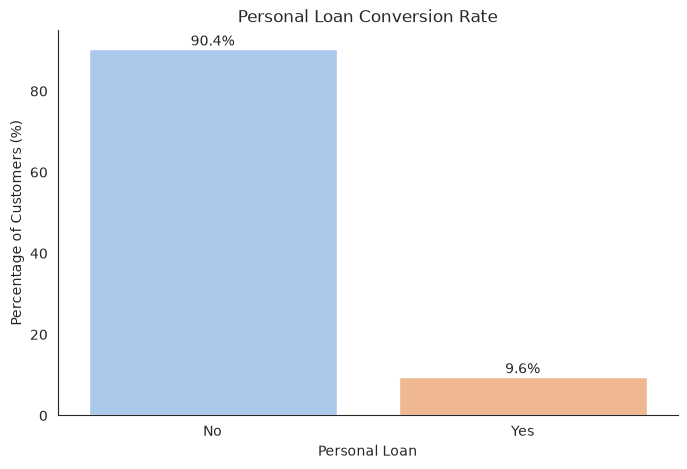

In [204]:
fig, ax = plt.subplots(figsize=(8, 5))

sns.countplot(
    data=data,
    x="Personal Loan",
    hue="Personal Loan",
    order=[0, 1],
    stat="percent",
    legend=False,
    ax=ax,
)

for container in ax.containers:
  ax.bar_label(container, fmt="%.1f%%")

ax.set(
    title="Personal Loan Conversion Rate",
    xlabel="Personal Loan",
    ylabel="Percentage of Customers (%)",
    xticks=[0, 1],
    xticklabels=["No", "Yes"],
)

sns.despine()

# Saving the figure for the report
# plt.savefig("q1.svg")


Given that each identifier is unique, only 480 out of 5000 clients contracted a personal loan, corresponding to a campaign conversion rate of 9.6%.

### Question 2 : How are the different variables (age, income, education, etc.) distributed in the dataset?


#### Distribution of Age

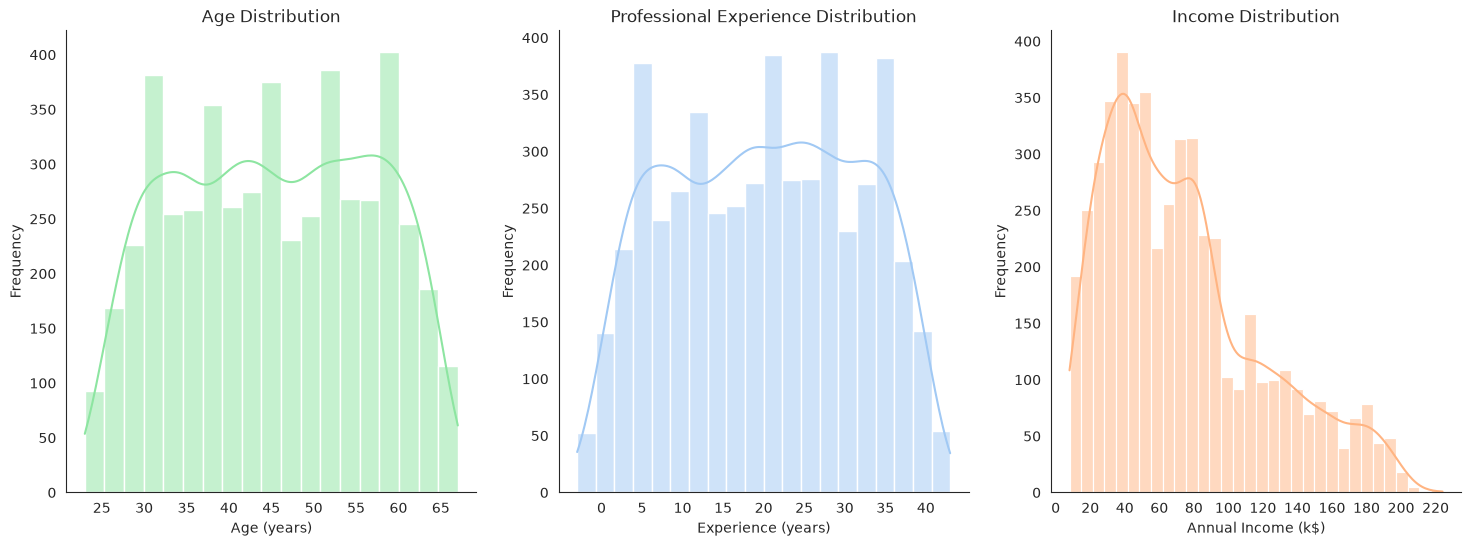

In [205]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
pastel = sns.color_palette("pastel")

sns.histplot(data['Age'], kde=True,ax=axes[0], color = pastel[2])
axes[0].set(title='Age Distribution',
       xlabel='Age (years)',
       ylabel='Frequency')
axes[0].set_xticks(np.arange(25, data['Age'].max(), 5))


sns.despine()


sns.histplot(data['Income'], kde=True, ax = axes[2], color = pastel[1])
axes[2].set(title='Income Distribution',
       xlabel='Annual Income (k$)',
       ylabel='Frequency')
axes[2].set_xticks(np.arange(0, data['Income'].max(), 20))

sns.histplot(df_q6['Experience'], kde=True, ax = axes[1])
axes[1].set(title='Professional Experience Distribution',
       xlabel='Experience (years)',
       ylabel='Frequency')
axes[1].set_xticks(np.arange(0, data['Experience'].max(), 5))
sns.despine()



In [206]:
# Recoding of Education variable to get "Undergduate","Graduate" and "Professional" labels.
data['Education_Label'] = df_q6['Education'].map({1: 'Undergraduate', 2: 'Graduate', 3: 'Professional'}, categories =  ["Undergraduate", "Graduate", "Professional"], ordered = True)
data['Education_Label'].value_counts(normalize=True) * 100

Education_Label
Undergraduate    41.92
Professional     30.02
Graduate         28.06
Name: proportion, dtype: float64

/tmp/ipykernel_16032/826785922.py:2: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:#d0bbff'` for the same effect.

  sns.countplot(data=data, x='Education_Label', hue='Education_Label', legend=True, ax=axes[0], color = pastel[4])
/tmp/ipykernel_16032/826785922.py:13: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:#ffb482'` for the same effect.

  sns.countplot(data=data, x='Family', hue='Family', color = pastel[1], ax=axes[1])


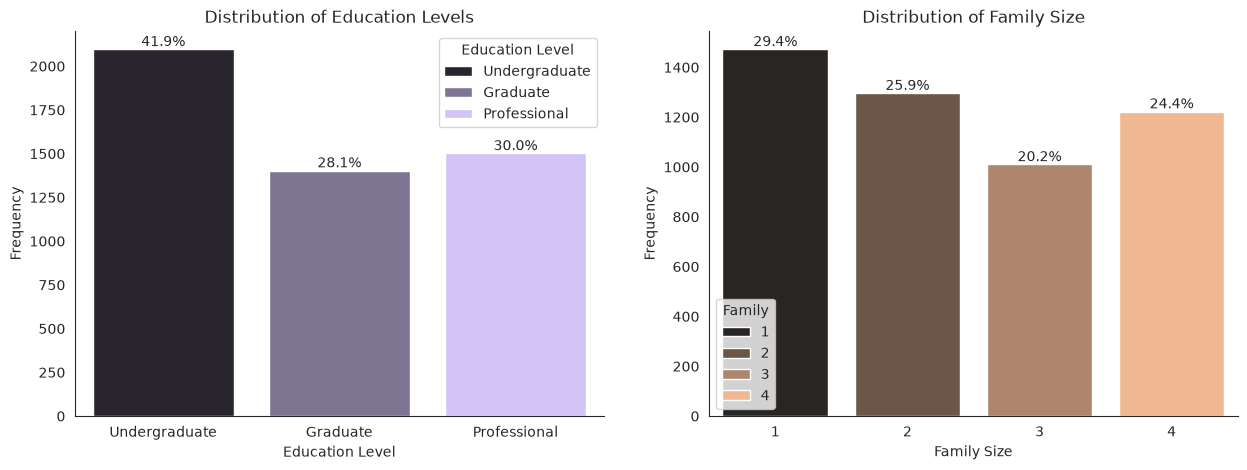

In [207]:
fig, axes = plt.subplots(1,2 ,figsize=(15, 5))
sns.countplot(data=data, x='Education_Label', hue='Education_Label', legend=True, ax=axes[0], color = pastel[4])
axes[0].set(title='Distribution of Education Levels', xlabel='Education Level', ylabel='Frequency')
axes[0].legend(title='Education Level')

# Display percentage labels
for container in axes[0].containers:
    labels = [f'{(bar.get_height() / data['Education_Label'].count() * 100):.1f}%' for bar in container]
    axes[0].bar_label(container, labels=labels)
sns.despine()


sns.countplot(data=data, x='Family', hue='Family', color = pastel[1], ax=axes[1])
axes[1].set(title='Distribution of Family Size', xlabel='Family Size', ylabel='Frequency')
sns.despine()

# Display percentage labels
for container in axes[1].containers:
    labels = [f'{(bar.get_height() / data["Family"].count() * 100):.1f}%' for bar in container]
    axes[1].bar_label(container, labels=labels)
sns.despine()



#### Distribution of Personal Loan, Securities Account, CD Account, Online and Credit Card


We recode the binary variables as boolean for simplicity. This helps us graph more accurate graphs.

In [208]:
# Recode binary variable names for better readability 
data = data.rename(columns={'CreditCard': 'Credit Card',
                              'Online': 'Online Facilities',
                              'CD Account': 'Certificate of Deposit Account'})
# Define all boolean variables
binary_cols = ['Personal Loan', 'Securities Account', 'Certificate of Deposit Account', 'Online Facilities', 'Credit Card']
# Melt the dataframe to long format for plotting
binary_df = data[binary_cols].melt(var_name='Variable', value_name='Response')
# Recode binary responses to 'Yes' and 'No' for better readability 
binary_df['Response'] = binary_df['Response'].map({0: 'No', 1: 'Yes'})

# Frequency table
counts_df = pd.crosstab(binary_df['Variable'], binary_df['Response'])
pct_df = pd.crosstab(binary_df['Variable'], binary_df['Response'], normalize='index') * 100
pd.concat([counts_df, pct_df.add_suffix(' (%)')], axis=1).round(1)

Response,No,Yes,No (%),Yes (%)
Variable,,,,
Certificate of Deposit Account,4698,302,94.0,6.0
Credit Card,3530,1470,70.6,29.4
Online Facilities,2016,2984,40.3,59.7
Personal Loan,4520,480,90.4,9.6
Securities Account,4478,522,89.6,10.4


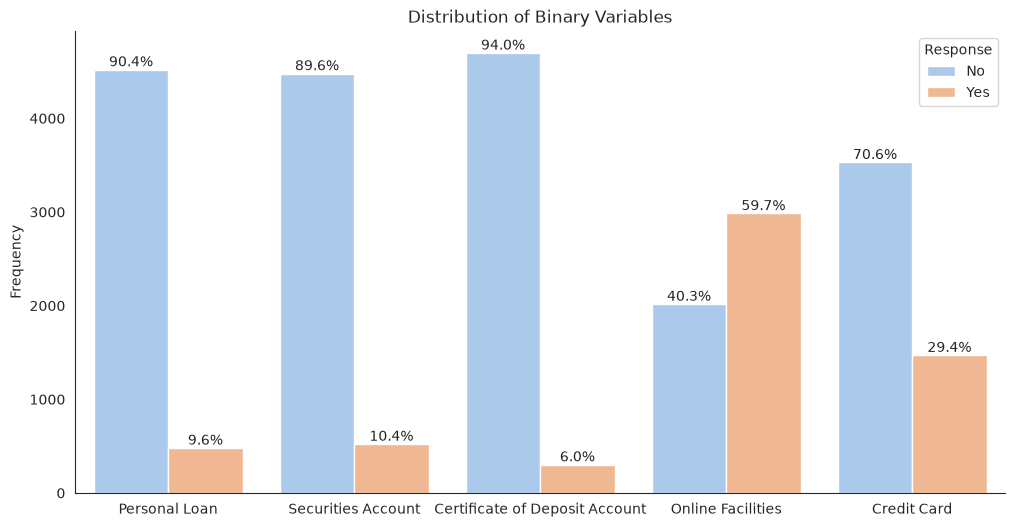

In [209]:
fig, ax = plt.subplots(figsize=(12, 6))
sns.countplot(data=binary_df, x='Variable', hue='Response', ax=ax)
ax.set(title='Distribution of Binary Variables', xlabel=None, ylabel='Frequency')
sns.despine()

# Adding percentage labels to the bars
totals = [data[col].count() for col in binary_cols] # Total counts for each binary variable
for container in ax.containers:
    labels = [f'{(bar.get_height() / tot * 100):.1f}%' for bar, tot in zip(container, totals)]
    ax.bar_label(container, labels=labels)
plt.show()

### Question 3 : How do the different variables interact with each other?


<Axes: >

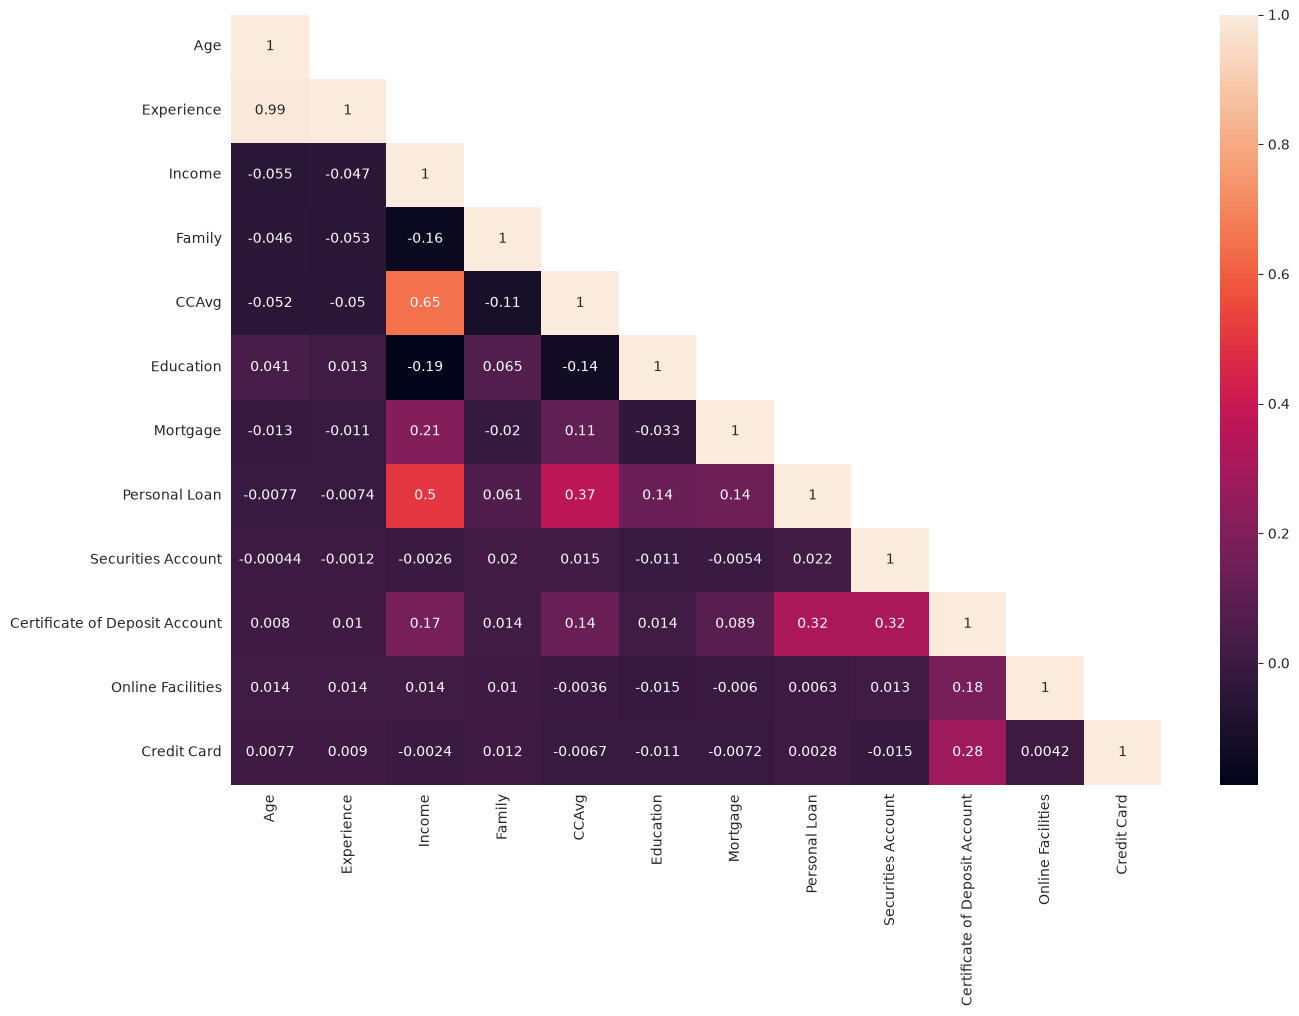

In [210]:

#Correlation matrix to see which features are interesting to interact.
df_corr = data.drop(columns=['Education_Label', 'ID', 'ZIP Code']).copy()
corr = df_corr.corr()

# Hiding the upper triangle matrix for clarity
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)

plt.figure(figsize=(15,10))
sns.heatmap(corr, mask=mask, annot= True)



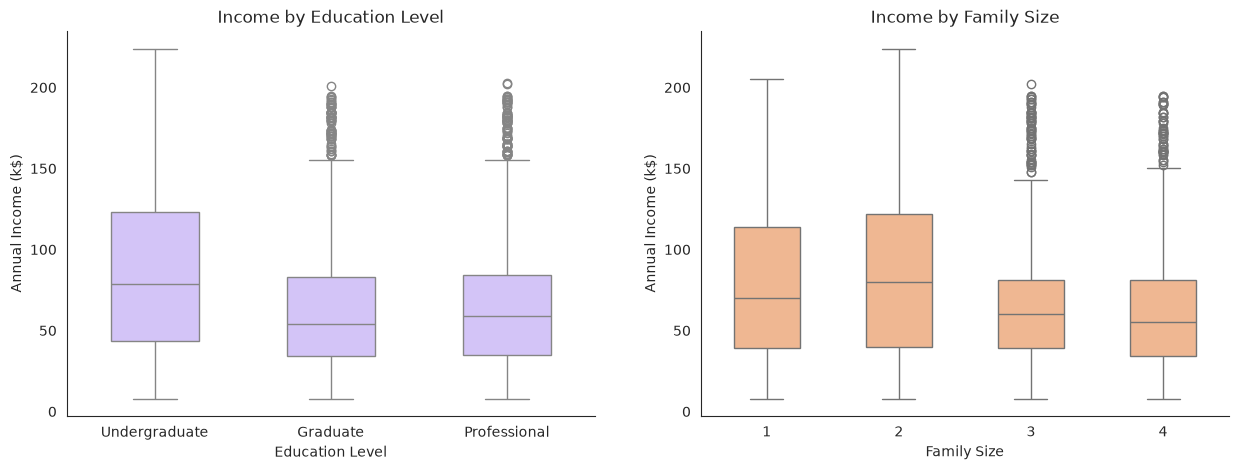

In [211]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.boxplot(data=data, x="Education_Label", y="Income",
            color=pastel[4], width=0.5, ax=axes[0])
axes[0].set(title="Income by Education Level", xlabel="Education Level", ylabel="Annual Income (k$)")
sns.boxplot(data=data, x="Family", y="Income", color=pastel[1], width=0.5, ax=axes[1])
axes[1].set(title="Income by Family Size", xlabel="Family Size", ylabel="Annual Income (k$)")
sns.despine()


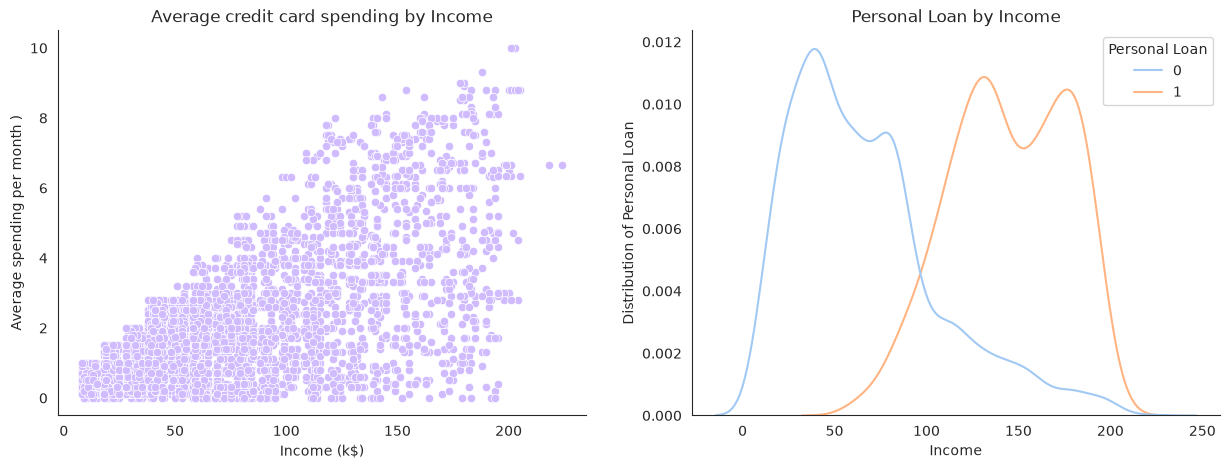

In [212]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.scatterplot(data=data, x="Income", y="CCAvg",
            color=pastel[4], ax=axes[0])
axes[0].set(title="Average credit card spending by Income", xlabel="Income (k$)", ylabel="Average spending per month )")
sns.kdeplot(data=data, x="Income", hue="Personal Loan", color=pastel[1],  ax=axes[1], common_norm=False)
axes[1].set(title="Personal Loan by Income", xlabel="Income", ylabel="Distribution of Personal Loan")
sns.despine()

In [213]:
# The above graph suggests an investigation within the high income customers.
high = data[data["Income"] > 100]

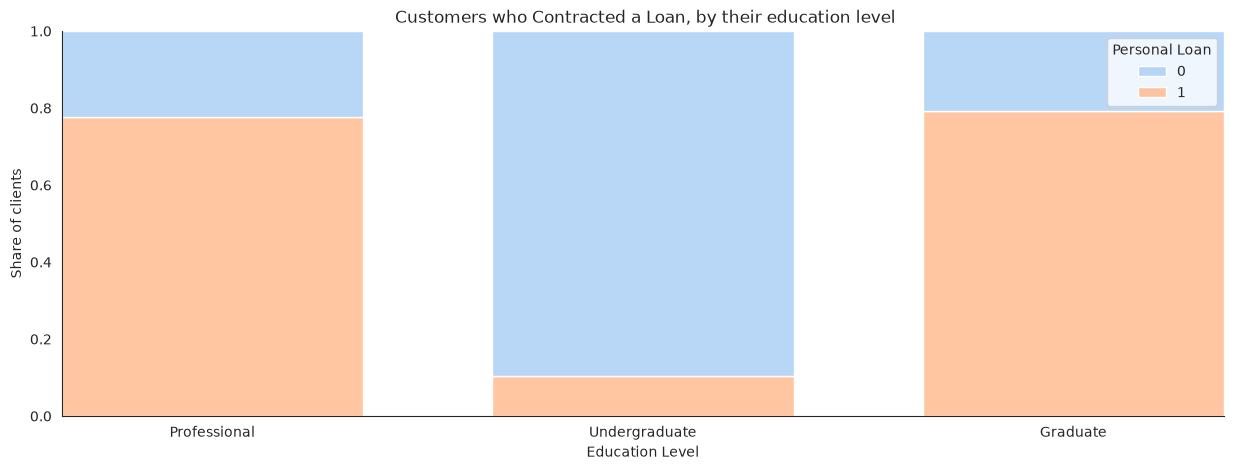

In [214]:
fig, ax = plt.subplots(1, figsize=(15, 5))
sns.histplot(data=high, x="Education_Label", hue="Personal Loan",
            color=pastel[4], ax = ax, common_norm="False",  stat = "proportion", hue_order = [0,1], multiple = "fill", shrink = 0.7)
ax.set(title=" Customers who Contracted a Loan, by their education level", xlabel="Education Level", ylabel="Share of clients")
sns.despine()

### Question 4 : Are age, income, education, etc. distributed similarly for customers who have security accounts and those who don't?

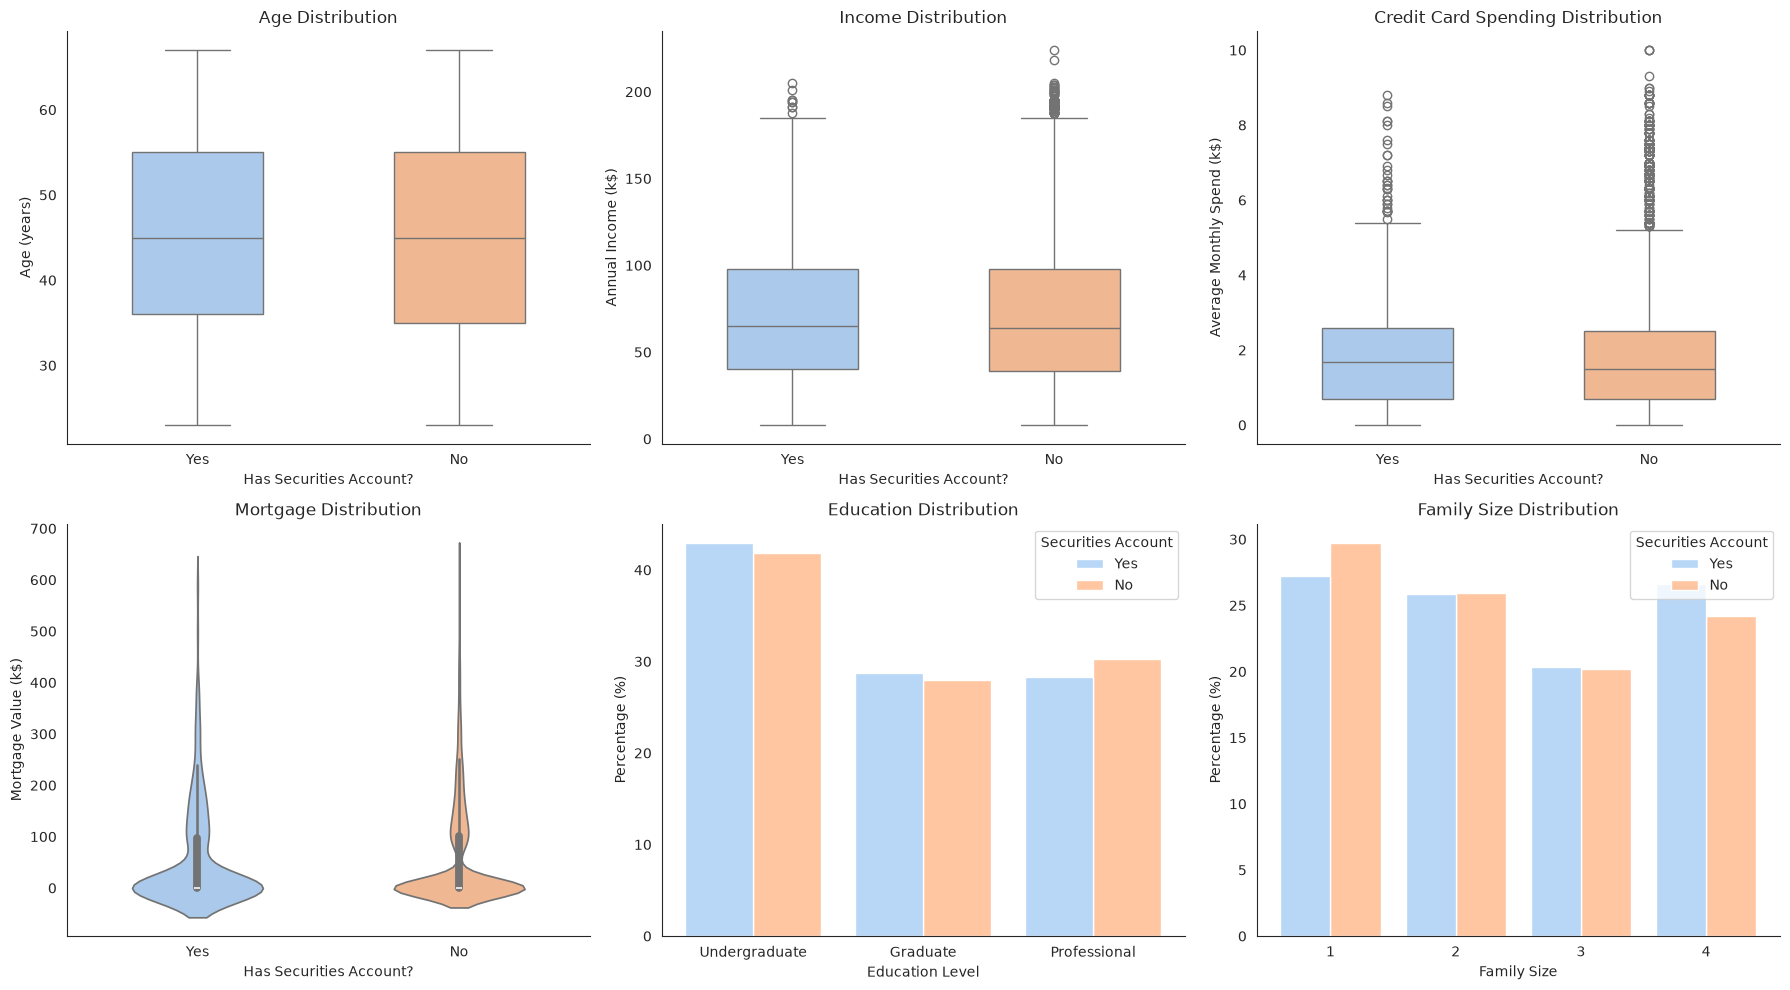

In [215]:
# Dataplot
plot_df = data.copy()
plot_df['Securities Account'] = plot_df['Securities Account'].map({0: 'No', 1: 'Yes'})

# Panel plot 
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

# Continuous variables
## Age
sns.boxplot(data=plot_df, x='Securities Account', y='Age', hue='Securities Account', legend=False,  width=0.5, ax=axes[0])
axes[0].set(title='Age Distribution', xlabel='Has Securities Account?', ylabel='Age (years)')
## Income
sns.boxplot(data=plot_df, x='Securities Account', y='Income', hue='Securities Account', legend=False,  width=0.5, ax=axes[1])
axes[1].set(title='Income Distribution', xlabel='Has Securities Account?', ylabel='Annual Income (k$)')
## Average Credit Card Spending
sns.boxplot(data=plot_df, x='Securities Account', y='CCAvg', hue='Securities Account', legend=False,  width=0.5, ax=axes[2])
axes[2].set(title='Credit Card Spending Distribution', xlabel='Has Securities Account?', ylabel='Average Monthly Spend (k$)')
## House Mortgage Value
sns.violinplot(data=plot_df, x='Securities Account', y='Mortgage', hue='Securities Account', legend=False,  width=0.5, ax=axes[3])
axes[3].set(title='Mortgage Distribution', xlabel='Has Securities Account?', ylabel='Mortgage Value (k$)')

# Categorical variables
## Education 
sns.histplot(data=plot_df, x='Education_Label', hue='Securities Account', multiple='dodge', stat='percent', common_norm=False, 
             shrink=0.8,  ax=axes[4])
axes[4].set(title='Education Distribution', xlabel='Education Level', ylabel='Percentage (%)')
## Family Size
sns.histplot(data=plot_df, x='Family', hue='Securities Account', multiple='dodge', stat='percent', common_norm=False, 
             discrete=True, shrink=0.8,  ax=axes[5])
axes[5].set(title='Family Size Distribution', xlabel='Family Size', ylabel='Percentage (%)')
axes[5].set_xticks(sorted(plot_df['Family'].unique()))



# Display
sns.despine()
plt.tight_layout()
plt.show()

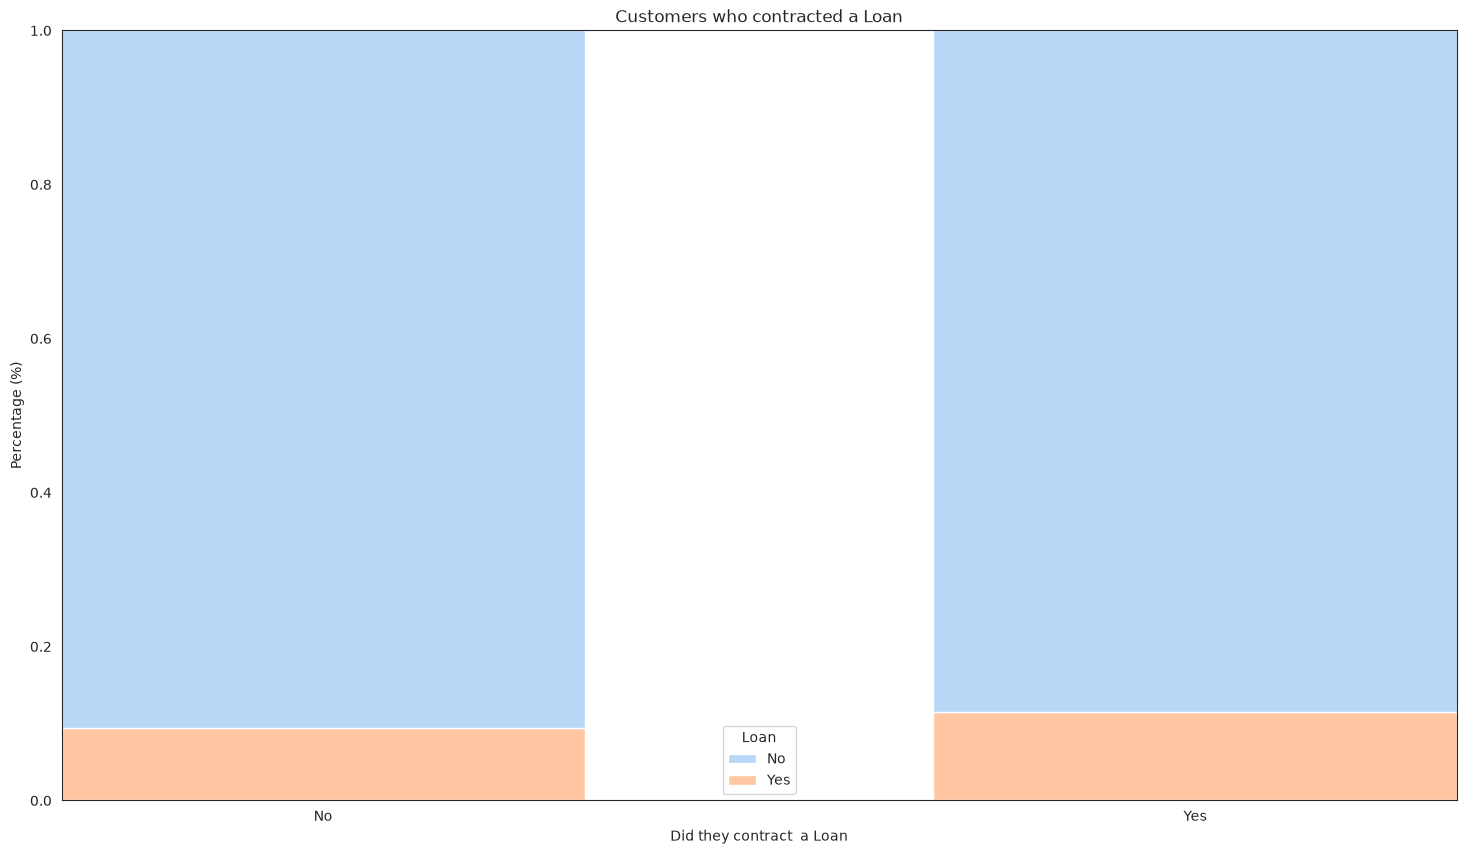

In [216]:
plot_df["Loan"] = plot_df["Personal Loan"].map({0: "No", 1: "Yes"})

fig, ax = plt.subplots(1, figsize = (18,10))
sns.histplot(data=plot_df.sort_values("Securities Account"), x="Securities Account", hue="Loan", multiple="fill",stat = "proportion", discrete=True, shrink=0.6)
ax.set(title='Customers who contracted a Loan', xlabel='Did they contract  a Loan', ylabel='Percentage (%)')
ax.set_xticks(sorted(plot_df['Personal Loan'].unique()))

### Question 5 : Are age, income, education, etc. distributed similarly for customers who have CD accounts and those who don't?

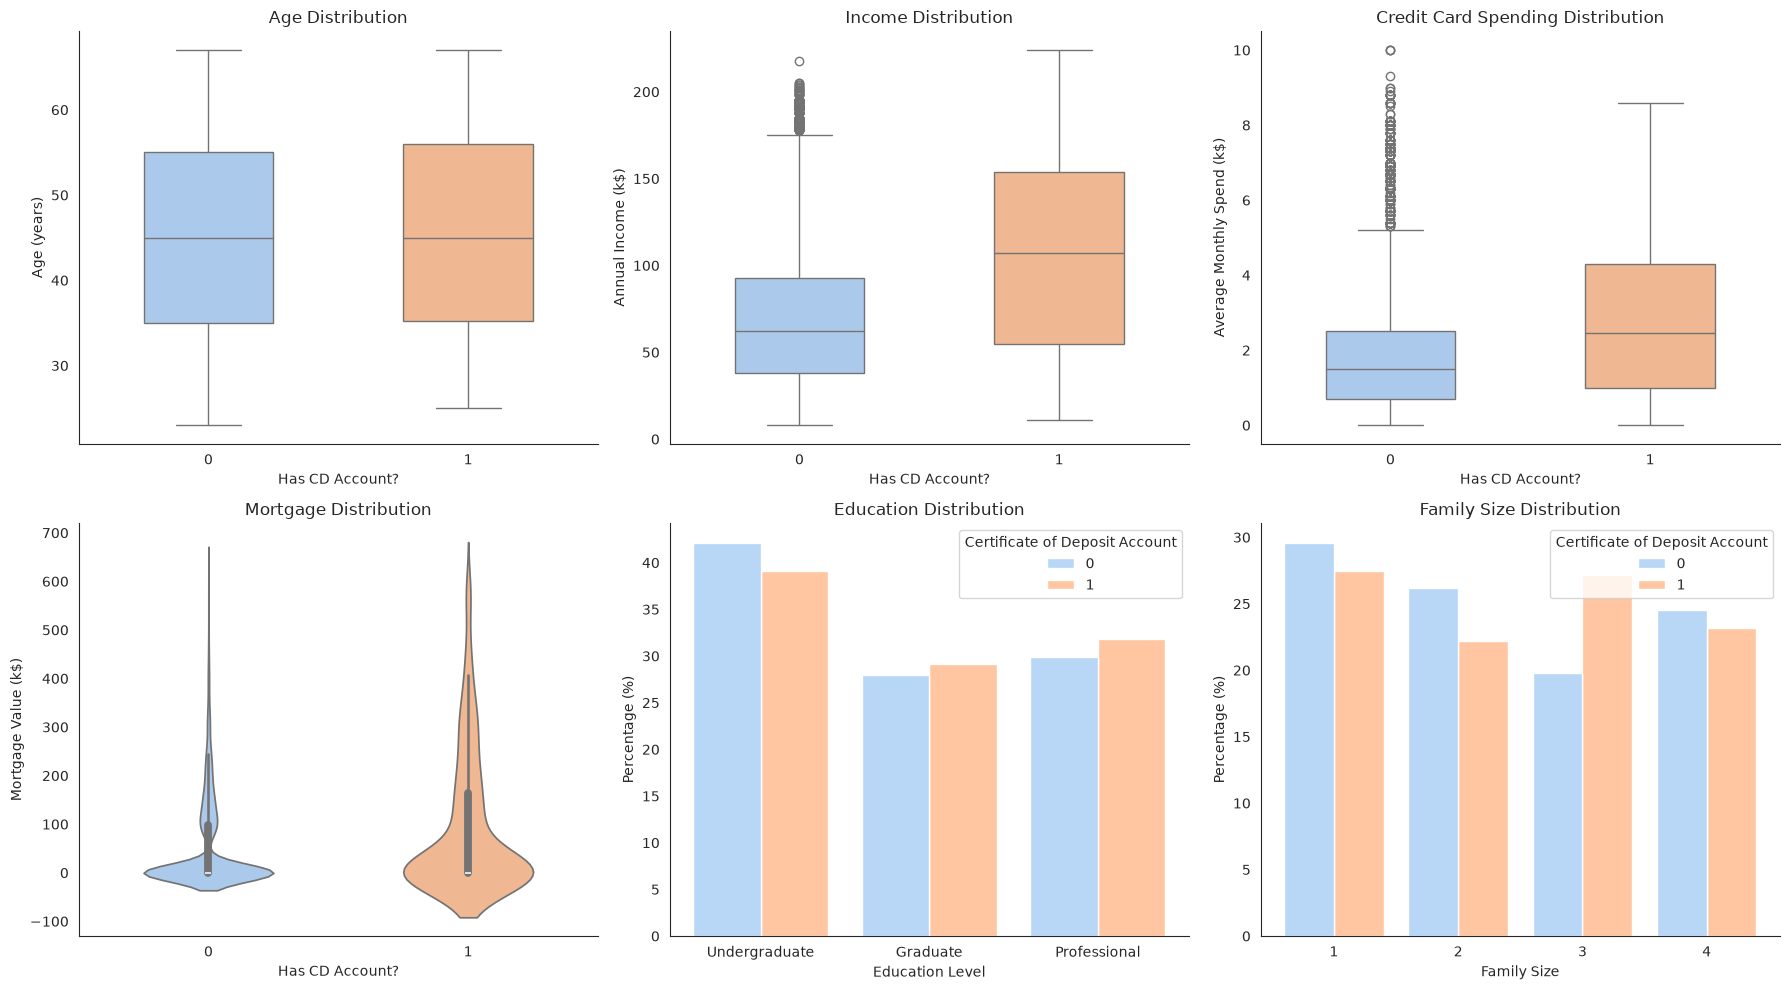

In [217]:
# Dataplot
plot_df = data.copy()

# Panel plot 
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

# Continuous variables
## Age
sns.boxplot(data=plot_df, x='Certificate of Deposit Account', y='Age', hue='Certificate of Deposit Account', legend=False,  width=0.5, ax=axes[0])
axes[0].set(title='Age Distribution', xlabel='Has CD Account?', ylabel='Age (years)')
## Income
sns.boxplot(data=plot_df, x='Certificate of Deposit Account', y='Income', hue='Certificate of Deposit Account', legend=False,  width=0.5, ax=axes[1])
axes[1].set(title='Income Distribution', xlabel='Has CD Account?', ylabel='Annual Income (k$)')
## Average Credit Card Spending
sns.boxplot(data=plot_df, x='Certificate of Deposit Account', y='CCAvg', hue='Certificate of Deposit Account', legend=False,  width=0.5, ax=axes[2])
axes[2].set(title='Credit Card Spending Distribution', xlabel='Has CD Account?', ylabel='Average Monthly Spend (k$)')
## House Mortgage Value
sns.violinplot(data=plot_df, x='Certificate of Deposit Account', y='Mortgage', hue='Certificate of Deposit Account', legend=False,  width=0.5, ax=axes[3])
axes[3].set(title='Mortgage Distribution', xlabel='Has CD Account?', ylabel='Mortgage Value (k$)')

# Categorical variables
## Education 
sns.histplot(data=plot_df, x='Education_Label', hue='Certificate of Deposit Account', multiple='dodge', stat='percent', common_norm=False, 
             shrink=0.8,  ax=axes[4])
axes[4].set(title='Education Distribution', xlabel='Education Level', ylabel='Percentage (%)')
## Family Size
sns.histplot(data=plot_df, x='Family', hue='Certificate of Deposit Account', multiple='dodge', stat='percent', common_norm=False, 
             discrete=True, shrink=0.8,  ax=axes[5])
axes[5].set(title='Family Size Distribution', xlabel='Family Size', ylabel='Percentage (%)')
axes[5].set_xticks(sorted(plot_df['Family'].unique()))

# Display
sns.despine()
plt.tight_layout()
plt.show()

In [218]:
#Would be interesting to have the t-test but it is clear that the difference is significant. 

print(data.groupby("Certificate of Deposit Account")["Income"].agg([np.mean,np.std]).round(2).to_markdown())

|   Certificate of Deposit Account |   mean |   std |
|---------------------------------:|-------:|------:|
|                                0 |  71.79 | 44.68 |
|                                1 | 104.59 | 54.9  |


<Axes: xlabel='CD', ylabel='Proportion'>

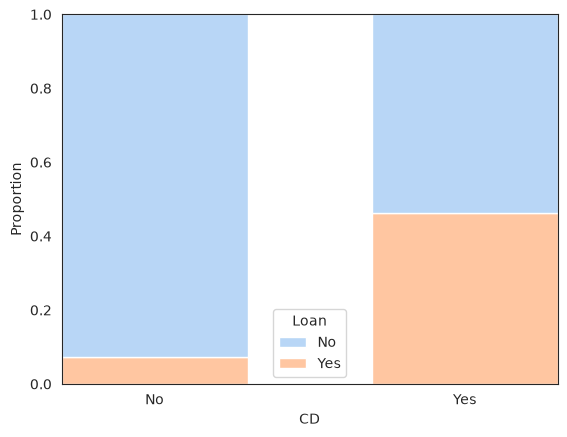

In [219]:
plot_df["Loan"] = plot_df["Personal Loan"].map({0: "No", 1: "Yes"})
plot_df["CD"] = plot_df["Certificate of Deposit Account"].map({0: "No", 1: "Yes"})

sns.histplot(data=plot_df, x="CD", hue="Loan", multiple="fill",stat = "proportion", discrete=True, shrink=0.6)

## Question 6

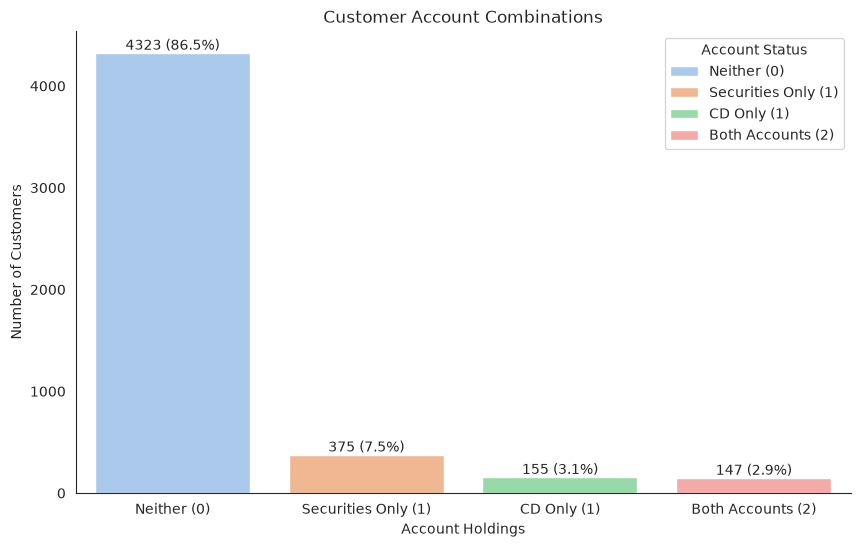

In [220]:
# Creating a label for each combination of Securities Account and Certificate of Deposit Account
df_q6 = data.copy()

conditions = [(df_q6['Securities Account'] == 0) & (df_q6['Certificate of Deposit Account'] == 0),
              (df_q6['Securities Account'] == 1) & (df_q6['Certificate of Deposit Account'] == 0),
              (df_q6['Securities Account'] == 0) & (df_q6['Certificate of Deposit Account'] == 1),
              (df_q6['Securities Account'] == 1) & (df_q6['Certificate of Deposit Account'] == 1)]
choices = ['Neither (0)', 'Securities Only (1)', 'CD Only (1)', 'Both Accounts (2)']
df_q6['Account_Status'] = np.select(conditions, choices, default='Unknown')

# Plot
fig, ax = plt.subplots(figsize=(10, 6))
order = ['Neither (0)', 'Securities Only (1)', 'CD Only (1)', 'Both Accounts (2)'] # Condition ordering
sns.countplot(data=df_q6, x='Account_Status', hue='Account_Status', hue_order=order, order=order,
              legend=True, ax=ax)
ax.set(title='Customer Account Combinations', xlabel='Account Holdings', ylabel='Number of Customers')
ax.legend(title='Account Status')

# Counts and percentages on top of the bars
total_customers = len(df_q6)
for container in ax.containers:
    labels = [f'{int(bar.get_height())} ({(bar.get_height() / total_customers * 100):.1f}%)' 
              for bar in container] 
    ax.bar_label(container, labels=labels)
sns.despine()
plt.show()

## Question 7

In [221]:
# Pearson Correlation with Personal Loan
# As said above, we drop Experience since it's perfectly correlated with Age
corr_loan = data.corr(numeric_only=True)['Personal Loan'].drop(labels=['Personal Loan', 'ID', 'ZIP Code', 'Experience']).sort_values(ascending=False)
display(corr_loan.to_frame().round(3))

,Personal Loan
Income,0.502
CCAvg,0.367
Certificate of Deposit Account,0.316
Mortgage,0.142
Education,0.137
Family,0.061
Securities Account,0.022
Online Facilities,0.006
Credit Card,0.003
Age,-0.008


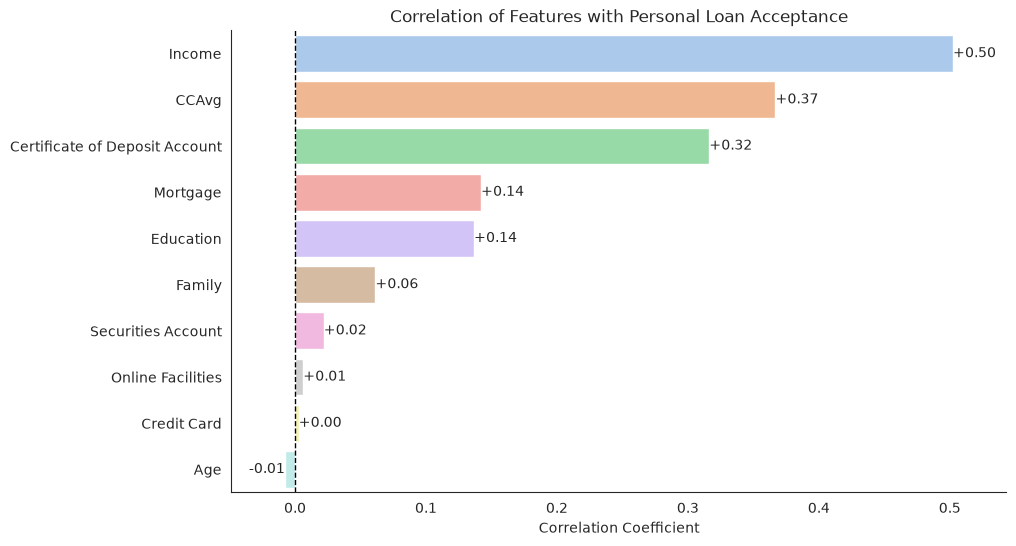

In [222]:
fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(x=corr_loan.values, y=corr_loan.index, hue=corr_loan.index, ax=ax)
ax.set(title='Correlation of Features with Personal Loan Acceptance', 
       xlabel='Correlation Coefficient', 
       ylabel=None)
ax.axvline(x=0, color='black', linewidth=1, linestyle='--')
for container in ax.containers:
    ax.bar_label(container, fmt='%+.2f') 
ax.margins(x=0.08) # X-axis margin for percentage labels
sns.despine()
plt.show()

In [223]:
## Logit regression 

## Question 8

In [ ]:
from sklearn.tree import DecisionTreeClassifier
features = ["Age", "Income", "Family", "CCAvg", "Education", "Mortgage",
            "Securities Account", "Certificate of Deposit Account", "Online Facilities", "Credit Card"]
y = data["Personal Loan"]
X = data[features]
## Tree
# We use grid search and trainsplits; most of the code is re-used from our Machine Learning class with Pr Rossi.
from sklearn import model_selection
X_tv, X_test, Y_tv, Y_test = model_selection.train_test_split(
X, y, test_size = 0.2, stratify = y, random_state=0)
from sklearn.model_selection import StratifiedShuffleSplit
v_split = StratifiedShuffleSplit(n_splits=4, train_size=0.75, random_state=0) 

algorithm_params = {
    'min_samples_split': [2, 10, 20, 40, 60, 80, 100, 150, 200, 300],
    'max_depth': list(range(2, 6, 2)),
    'min_impurity_decrease': np.linspace(0, 0.005, 11),
}

from sklearn.model_selection import GridSearchCV
grid_search_rmse = GridSearchCV(DecisionTreeClassifier(random_state = 0),algorithm_params, cv = v_split)

grid_search_rmse = grid_search_rmse.fit(X_tv, Y_tv)

In [233]:
results = pd.DataFrame(grid_search_rmse.cv_results_)
results[['param_min_samples_split', 'param_max_depth',
         'param_min_impurity_decrease','mean_test_score']].sort_values('mean_test_score', ascending= False).head(10)

,param_min_samples_split,param_max_depth,param_min_impurity_decrease,mean_test_score
243,40,None,0.0010,0.98775
233,40,None,0.0005,0.98775
223,40,None,0.0000,0.98775
242,20,None,0.0010,0.98725
240,2,None,0.0010,0.98700
241,10,None,0.0010,0.98700
253,40,None,0.0015,0.98675
250,2,None,0.0015,0.98675
251,10,None,0.0015,0.98675
252,20,None,0.0015,0.98675


[Text(0.5, 0.9, 'Income <= 113.5\ngini = 0.174\nsamples = 4000\nvalue = [3616, 384]'),
 Text(0.2631578947368421, 0.7, 'CCAvg <= 2.95\ngini = 0.042\nsamples = 3229\nvalue = [3159, 70]'),
 Text(0.381578947368421, 0.8, 'True  '),
 Text(0.10526315789473684, 0.5, 'Income <= 106.5\ngini = 0.007\nsamples = 2982\nvalue = [2972, 10]'),
 Text(0.05263157894736842, 0.3, 'gini = 0.0\nsamples = 2907\nvalue = [2907, 0]'),
 Text(0.15789473684210525, 0.3, 'Family <= 3.5\ngini = 0.231\nsamples = 75\nvalue = [65, 10]'),
 Text(0.10526315789473684, 0.1, '\n  (...)  \n'),
 Text(0.21052631578947367, 0.1, '\n  (...)  \n'),
 Text(0.42105263157894735, 0.5, 'Certificate of Deposit Account <= 0.5\ngini = 0.368\nsamples = 247\nvalue = [187, 60]'),
 Text(0.3684210526315789, 0.3, 'Income <= 92.5\ngini = 0.31\nsamples = 224\nvalue = [181, 43]'),
 Text(0.3157894736842105, 0.1, '\n  (...)  \n'),
 Text(0.42105263157894735, 0.1, '\n  (...)  \n'),
 Text(0.47368421052631576, 0.3, 'gini = 0.386\nsamples = 23\nvalue = [6, 17

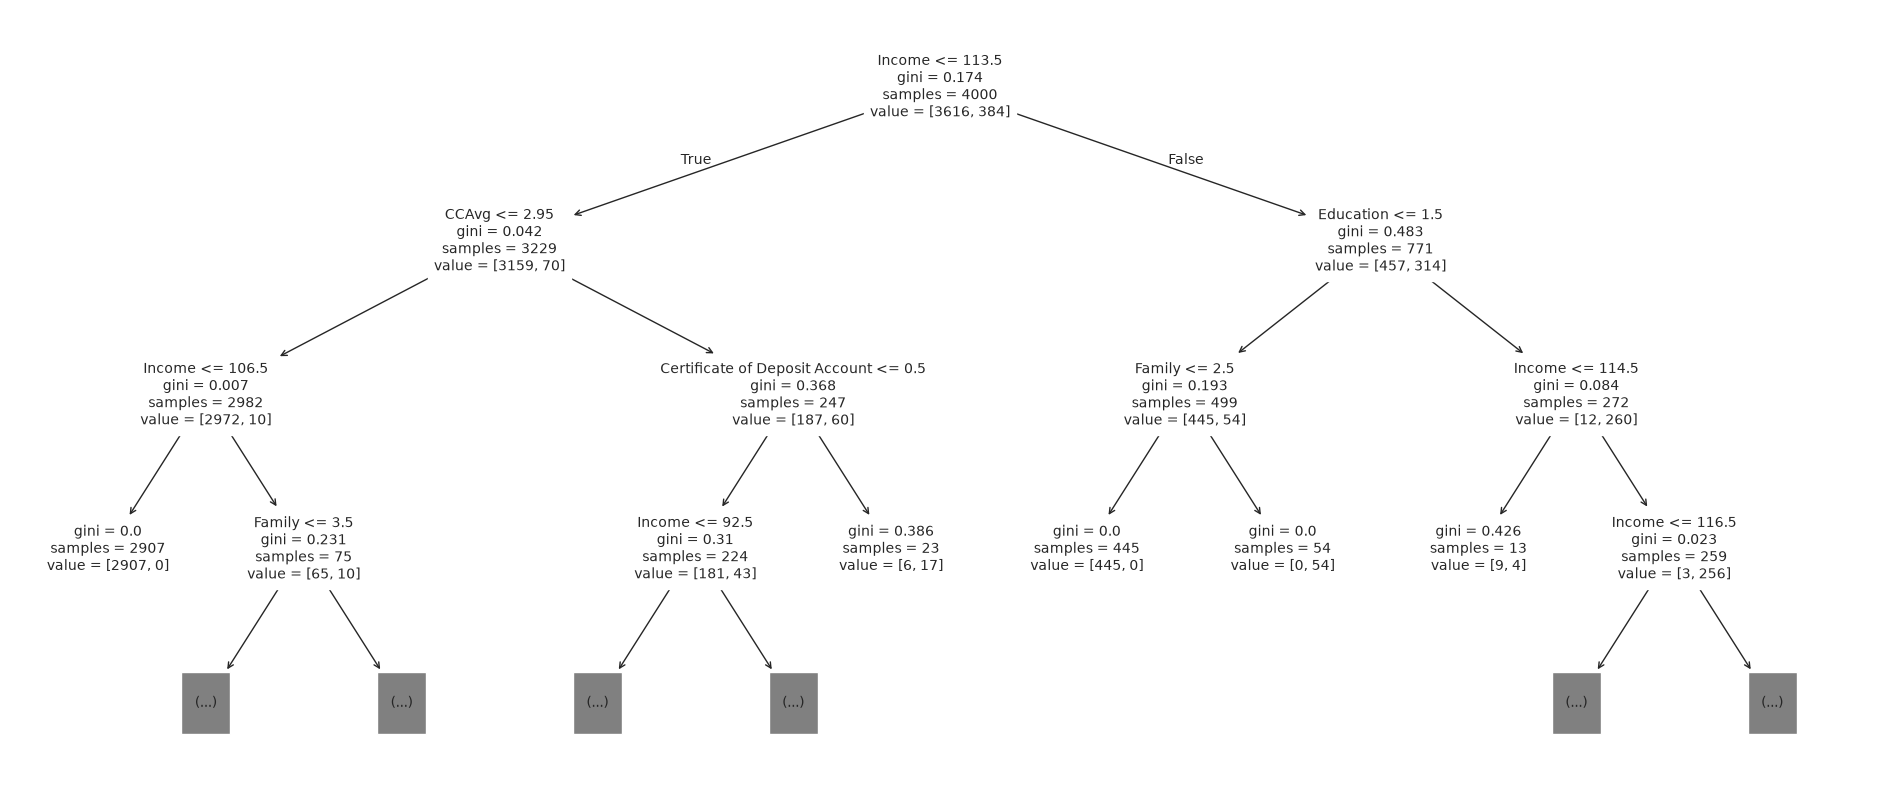

In [234]:
from sklearn.tree import plot_tree
fig, ax = plt.subplots(figsize=(24, 10))

best = grid_search_rmse.best_estimator_
plot_tree(best, feature_names= X.columns, ax = ax, max_depth= 3, fontsize = 10)

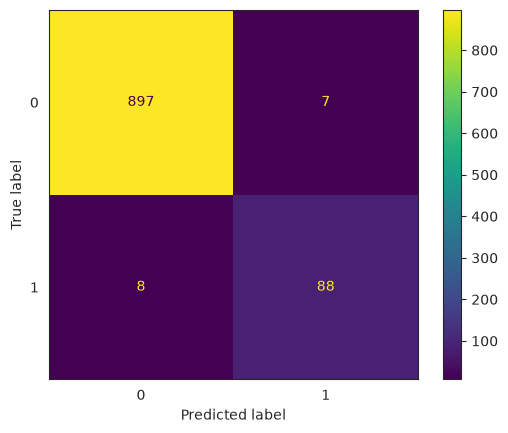

In [235]:
from sklearn.metrics import ConfusionMatrixDisplay
ConfusionMatrixDisplay.from_estimator(best,X_test, Y_test)